# Cell-wise RMSE / MAE Tables and Bar Charts

This notebook assembles the seven CMU target-cell tables and the cross-cell
primary-adapted RMSE/MAE figures from recorded framework metric files. It
does not recompute metrics from prediction trajectories.

DTNN and TATN use their completed five-repeat formal runs. Their source-only
and adapted entries are read from each run's summary file, so the displayed
values are means across five repeats. TATN uses the verified
`ns_relabel_v2` manifest and is no longer excluded. Frameworks with genuine
target-label budget sweeps retain the 1%, 5%, 10%, 40%, and Full columns;
unsupervised methods appear only in Source-only and Primary adapted.


In [20]:
"""Code Cell 1 -- imports, Drive mount, and Drive paths.

Mirrors notebook 37's Code Cell 1/2 approach: DRIVE_ROOT / OUTPUT_ROOT are
hardcoded directly against the mounted Drive (same convention as
`configs/paths/colab_drive.yaml`'s drive_root / output_root on the repo
side), rather than reading that yaml file from a cloned repo checkout --
this notebook does not assume the repo is checked out inside the Colab
runtime at all, only that Drive is mounted."""

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Running on Colab: mount Google Drive so DRIVE_ROOT below resolves.
# No-op (and harmless) outside Colab.
try:
    import google.colab  # noqa: F401

    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
except ImportError:
    pass

DRIVE_ROOT = Path("/content/drive/MyDrive/battery_soc_benchmark")
OUTPUT_ROOT = DRIVE_ROOT / "outputs"
BENCH_ROOT = OUTPUT_ROOT / "benchmarks" / "panasonic_to_cmu_evtol"

print("DRIVE_ROOT  :", DRIVE_ROOT)
print("OUTPUT_ROOT :", OUTPUT_ROOT)
print("BENCH_ROOT  :", BENCH_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DRIVE_ROOT  : /content/drive/MyDrive/battery_soc_benchmark
OUTPUT_ROOT : /content/drive/MyDrive/battery_soc_benchmark/outputs
BENCH_ROOT  : /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol


In [21]:
"""Code Cell 2 -- configuration: cells, budget map, per-framework paths."""

# ---- Core seven target cells (fixed; validated against every framework's
# run_metadata.json "cells" list and manifest cell_id values). ----
CORE_CELLS = ["VAH01", "VAH17", "VAH27", "VAH30", "VAH15", "VAH12", "VAH11"]

# ---- Verified budget display mapping (see title-cell note 1 above: 40%
# confirmed empirically from the manifest, not assumed from an example). ----
BUDGET_DISPLAY_MAP = {
    "zero_shot": "Source-only",
    "source_only": "Source-only",
    "1pct": "1%",
    "budget_1pct": "1%",
    "5pct": "5%",
    "budget_5pct": "5%",
    "10pct": "10%",
    "budget_10pct": "10%",
    "partial": "40%",
    "vidal_partial": "40%",
    "full": "Full",
    "vidal_full": "Full",
}
# Column order for the wide display tables.
BUDGET_COLUMN_ORDER = ["Source-only", "1%", "5%", "10%", "40%", "Full"]

# Display row order (framework display names, top to bottom).
FRAMEWORK_ROW_ORDER = [
    "Vidal Fine-tuning",
    "CNN-LSTM",
    "TCN",
    "Transformer Encoder",
    "DTNN",
    "DARM",
    "SFTNN (MED)",
    "TATN",
]

# ---- Vidal: six independent output roots, one cell_metrics.csv each. ----
# Real path confirmed:
# .../outputs/benchmarks/panasonic_to_cmu_evtol/vidal/<setting>/seed_42/<run_id>/
VIDAL_ROOT = BENCH_ROOT / "vidal"
VIDAL_SEED = 42
# setting -> preferred run_id. "latest" means: pick the most recently
# modified run_id folder under vidal/<setting>/seed_42/ at run time.
VIDAL_SETTINGS = ["zero_shot", "budget_1pct", "budget_5pct", "budget_10pct", "vidal_partial", "vidal_full"]
VIDAL_PREFERRED_RUN_ID = {
    "zero_shot": "20260916_184550",
    "budget_1pct": "20260916_184841",
    "budget_5pct": "20260916_185539",
    "budget_10pct": "20260916_190309",
    "vidal_partial": "20260916_191123",
    "vidal_full": "20260916_192416",
}

# ---- Backbone: one shared cell_metrics.csv, split by `model`. ----
BACKBONE_DIR = BENCH_ROOT / "backbone_transfer_ns_relabel_v2"
BACKBONE_CELL_METRICS = BACKBONE_DIR / "cell_metrics.csv"
BACKBONE_MODEL_TO_DISPLAY_NAME = {
    "cnn_lstm": "CNN-LSTM",
    "tcn": "TCN",
    "transformer_encoder": "Transformer Encoder",
}

# ---- DTNN: formal run, five-repeat means in formal/summary.csv.
# Source training uses 2000 epochs and adaptation uses 330 epochs. ----
# Real path confirmed:
# .../outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/{screening,formal}/
DTNN_DIR = BENCH_ROOT / "bian_2021" / "initial_soc_70_v2"
DTNN_SCREENING_METRICS = DTNN_DIR / "screening" / "metrics.csv"
DTNN_FORMAL_METRICS = DTNN_DIR / "formal" / "metrics.csv"
DTNN_FORMAL_SUMMARY = DTNN_DIR / "formal" / "summary.csv"  # one row per cell x method
DTNN_TABLE_SOURCE = "formal"  # reads formal/summary.csv directly

# ---- DARM: single unsupervised method, no budget sweep. ----
DARM_DIR = BENCH_ROOT / "liu_2025_darm_ns_relabel_v2_e30_clean"
DARM_CONDITION_METRICS = DARM_DIR / "condition_metrics.csv"

# ---- SFTNN: single unsupervised method (MED), no budget sweep. ----
SFTNN_DIR = BENCH_ROOT / "sftnn_med_transfer_ns_relabel_v2"
SFTNN_CELL_METRICS = SFTNN_DIR / "cell_metrics.csv"

# ---- TATN: verified current-protocol formal run, five-repeat summary. ----
TATN_DIR = BENCH_ROOT / "tatn_ns_relabel_v2_unsupervised_formal"
TATN_SUMMARY = TATN_DIR / "summary.csv"
TATN_PROTOCOL_CONFIRMED = True

# Manifest hash shared by Backbone / DARM / SFTNN / Vidal in the current
# protocol -- used only for the inventory printout's cross-check, not
# re-derived here.
CURRENT_PROTOCOL_MANIFEST_SHA256 = "0e3de73a6ae76f6a79fb17feb02390f91e6b288224f40afcdf538b65605532cb"

OUTPUT_DIR = Path("metric_table_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("CORE_CELLS:", CORE_CELLS)
print("BUDGET_DISPLAY_MAP (verified against manifest, see note 1):")
for k, v in BUDGET_DISPLAY_MAP.items():
    print(f"    {k!r:16s} -> {v!r}")


CORE_CELLS: ['VAH01', 'VAH17', 'VAH27', 'VAH30', 'VAH15', 'VAH12', 'VAH11']
BUDGET_DISPLAY_MAP (verified against manifest, see note 1):
    'zero_shot'      -> 'Source-only'
    'source_only'    -> 'Source-only'
    '1pct'           -> '1%'
    'budget_1pct'    -> '1%'
    '5pct'           -> '5%'
    'budget_5pct'    -> '5%'
    '10pct'          -> '10%'
    'budget_10pct'   -> '10%'
    'partial'        -> '40%'
    'vidal_partial'  -> '40%'
    'full'           -> 'Full'
    'vidal_full'     -> 'Full'


In [22]:
"""Code Cell -- real-Drive path existence diagnostics.

Prints the absolute path and exists=True/False for every top-level metric
source this notebook reads, BEFORE any loader runs. This is a real-Drive
check, not a substitute for the synthetic smoke test (which validates the
parsing/table-building logic against fixtures); this cell only validates
that the paths above actually resolve to something in the currently
mounted Drive."""

_diagnostic_paths = {
    "VIDAL_ROOT": VIDAL_ROOT,
    "DTNN_SCREENING_METRICS": DTNN_SCREENING_METRICS,
    "DTNN_FORMAL_SUMMARY": DTNN_FORMAL_SUMMARY,
    "BACKBONE_CELL_METRICS": BACKBONE_CELL_METRICS,
    "DARM_CONDITION_METRICS": DARM_CONDITION_METRICS,
    "SFTNN_CELL_METRICS": SFTNN_CELL_METRICS,
    "TATN_SUMMARY": TATN_SUMMARY,
}

print("=" * 78)
print("PATH EXISTENCE DIAGNOSTICS (real Drive, checked before loading)")
print("=" * 78)
_any_missing = False
for name, p in _diagnostic_paths.items():
    exists = p.exists()
    _any_missing = _any_missing or not exists
    print(f"{name:24s} {str(p.resolve()) if exists else str(p):90s} exists={exists}")
if _any_missing:
    print("\n[WARNING] One or more expected paths are missing on this Drive mount. "
          "The corresponding loader below will fall back to run_status='missing' rows "
          "(em-dash in the tables) rather than raising -- but this should be investigated "
          "before trusting the resulting table.")
else:
    print("\nAll checked paths exist.")


PATH EXISTENCE DIAGNOSTICS (real Drive, checked before loading)
VIDAL_ROOT               /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/vidal exists=True
DTNN_SCREENING_METRICS   /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/screening/metrics.csv exists=True
DTNN_FORMAL_SUMMARY      /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/bian_2021/initial_soc_70_v2/formal/summary.csv exists=True
BACKBONE_CELL_METRICS    /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/backbone_transfer_ns_relabel_v2/cell_metrics.csv exists=True
DARM_CONDITION_METRICS   /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/liu_2025_darm_ns_relabel_v2_e30_clean/condition_metrics.csv exists=True
SFTNN_CELL_METRICS       /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cm

In [23]:
"""Code Cell 3 -- metric-unit normalization helper."""


def ensure_percent_scale(series: pd.Series, *, column_name: str = "") -> pd.Series:
    """Return `series` expressed in percent (0-100), auto-detecting whether
    it is already in percent or still a fraction (0-1).

    Detection: if the max absolute value is <= 1.5 we assume the series is
    a fraction and multiply by 100; otherwise we assume it is already a
    percent and leave it unchanged. 1.5 (not 1.0) tolerates a handful of
    slightly-above-1 fraction values from bias/error metrics without
    misclassifying a genuinely-percent column whose smallest cell errors
    happen to be < 1.5%.

    This mirrors the same heuristic used in notebook 37's predictions
    loader, applied here to metric-output files instead of raw
    predictions. Vidal's per-setting `cell_metrics.csv` is the one place
    in this notebook where it actually fires (its `overall_mae` /
    `overall_rmse` columns are fractions); every other framework's
    `*_percent`-named columns are already percent and pass through
    unchanged.
    """
    if series.empty:
        return series
    s = pd.to_numeric(series, errors="coerce")
    if s.dropna().empty:
        return s
    if s.abs().max() <= 1.5:
        return s * 100.0
    return s


In [24]:
"""Code Cell 4 -- per-framework metric loaders.

Each loader returns a list of dict records with this common schema (the
fields of `metric_long`):

cell_id, framework, model, setting, budget_label, budget_internal, method,
seed_or_repeat, rmse, mae, evaluation_unit, run_status, source_path,
source_file, is_primary_adapted, is_screening, formal_benchmark_eligible,
notes
"""

import csv


def _read_csv_safely(path: Path) -> pd.DataFrame | None:
    if not path.exists():
        return None
    return pd.read_csv(path)


def load_vidal_records() -> list[dict]:
    records = []
    for setting in VIDAL_SETTINGS:
        run_id = VIDAL_PREFERRED_RUN_ID.get(setting)
        setting_dir = VIDAL_ROOT / setting / f"seed_{VIDAL_SEED}"
        run_dir = setting_dir / run_id if run_id else None
        metrics_path = run_dir / "cell_metrics.csv" if run_dir else None
        df = _read_csv_safely(metrics_path) if metrics_path else None
        budget_label = BUDGET_DISPLAY_MAP.get(setting, setting)
        if df is None:
            for cell_id in CORE_CELLS:
                records.append(dict(
                    cell_id=cell_id, framework="Vidal Fine-tuning", model=None,
                    setting=setting, budget_label=budget_label, budget_internal=setting,
                    method="fine_tuned", seed_or_repeat=VIDAL_SEED, rmse=np.nan, mae=np.nan,
                    evaluation_unit="last_step_per_window", run_status="missing",
                    source_path=str(metrics_path) if metrics_path else str(setting_dir),
                    source_file="cell_metrics.csv", is_primary_adapted=(setting == "vidal_full"),
                    is_screening=False, formal_benchmark_eligible=False,
                    notes=f"No cell_metrics.csv found for Vidal setting={setting!r}",
                ))
            continue
        for _, row in df.iterrows():
            rmse = ensure_percent_scale(pd.Series([row.get("overall_rmse", np.nan)])).iloc[0]
            mae = ensure_percent_scale(pd.Series([row.get("overall_mae", np.nan)])).iloc[0]
            records.append(dict(
                cell_id=row["cell_id"], framework="Vidal Fine-tuning", model=None,
                setting=setting, budget_label=budget_label, budget_internal=setting,
                method="fine_tuned", seed_or_repeat=VIDAL_SEED, rmse=rmse, mae=mae,
                evaluation_unit="last_step_per_window", run_status="ok",
                source_path=str(metrics_path), source_file="cell_metrics.csv",
                is_primary_adapted=(setting == "vidal_full"), is_screening=False,
                formal_benchmark_eligible=False,
                notes=f"run_id={run_id}",
            ))
    return records


def load_backbone_records() -> list[dict]:
    records = []
    df = _read_csv_safely(BACKBONE_CELL_METRICS)
    if df is None:
        for model, display in BACKBONE_MODEL_TO_DISPLAY_NAME.items():
            for setting in ["zero_shot", "1pct", "5pct", "10pct", "partial", "full"]:
                for cell_id in CORE_CELLS:
                    records.append(dict(
                        cell_id=cell_id, framework=display, model=model, setting=setting,
                        budget_label=BUDGET_DISPLAY_MAP.get(setting, setting), budget_internal=setting,
                        method=("zero_shot" if setting == "zero_shot" else "fine_tuned"),
                        seed_or_repeat=42, rmse=np.nan, mae=np.nan, evaluation_unit="all_timesteps",
                        run_status="missing", source_path=str(BACKBONE_CELL_METRICS),
                        source_file="cell_metrics.csv", is_primary_adapted=(setting == "full"),
                        is_screening=False, formal_benchmark_eligible=False,
                        notes="cell_metrics.csv not found",
                    ))
        return records
    for _, row in df.iterrows():
        model = row["model"]
        display = BACKBONE_MODEL_TO_DISPLAY_NAME.get(model, model)
        setting = row["budget"]
        method = "zero_shot" if setting == "zero_shot" else "fine_tuned"
        records.append(dict(
            cell_id=row["cell_id"], framework=display, model=model, setting=setting,
            budget_label=BUDGET_DISPLAY_MAP.get(setting, setting), budget_internal=setting,
            method=method, seed_or_repeat=row.get("seed", 42),
            rmse=row.get("overall_rmse_percent", np.nan), mae=row.get("overall_mae_percent", np.nan),
            evaluation_unit="all_timesteps", run_status="ok",
            source_path=str(BACKBONE_CELL_METRICS), source_file="cell_metrics.csv",
            is_primary_adapted=(setting == "full"), is_screening=False,
            formal_benchmark_eligible=bool(row.get("formal_benchmark_eligible", False)),
            notes="",
        ))
    return records


def load_dtnn_records() -> list[dict]:
    records = []
    formal_path = DTNN_FORMAL_SUMMARY
    df = _read_csv_safely(formal_path)
    is_screening = False
    if df is None:
        for cell_id in CORE_CELLS:
            records.append(dict(
                cell_id=cell_id, framework="DTNN", model=None, setting="formal",
                budget_label="Source-only", budget_internal="source_only", method="Source only",
                seed_or_repeat=1, rmse=np.nan, mae=np.nan, evaluation_unit="all_timesteps",
                run_status="missing", source_path=str(formal_path), source_file="summary.csv",
                is_primary_adapted=False, is_screening=False, formal_benchmark_eligible=False,
                notes="DTNN formal metrics not found",
            ))
        return records
    for _, row in df.iterrows():
        method = row["method"]
        is_adapted = method == "Bian MDA"
        budget_label = "Source-only" if method == "Source only" else None
        budget_internal = "source_only" if method == "Source only" else "adapted_unsupervised"
        records.append(dict(
            cell_id=row["cell_id"], framework="DTNN", model=None, setting="formal",
            budget_label=budget_label, budget_internal=budget_internal, method=method,
            seed_or_repeat=row.get("repeat", row.get("seed", 1)),
            rmse=row.get("overall_rmse_percent", np.nan), mae=row.get("overall_mae_percent", np.nan),
            evaluation_unit="all_timesteps", run_status="ok",
            source_path=str(formal_path), source_file="summary.csv",
            is_primary_adapted=is_adapted, is_screening=is_screening,
            formal_benchmark_eligible=False,
            notes=("DTNN formal run (source 2000 epochs, adaptation 330 epochs, five repeats); "
                   "five-repeat mean read directly from formal/summary.csv."),
        ))
    return records


def load_darm_records() -> list[dict]:
    records = []
    df = _read_csv_safely(DARM_CONDITION_METRICS)
    if df is None:
        for cell_id in CORE_CELLS:
            records.append(dict(
                cell_id=cell_id, framework="DARM", model=None, setting="condition",
                budget_label="Source-only", budget_internal="source_only", method="Source only",
                seed_or_repeat=42, rmse=np.nan, mae=np.nan, evaluation_unit="last_step_per_window",
                run_status="missing", source_path=str(DARM_CONDITION_METRICS),
                source_file="condition_metrics.csv", is_primary_adapted=False,
                is_screening=False, formal_benchmark_eligible=False,
                notes="condition_metrics.csv not found",
            ))
        return records
    for _, row in df.iterrows():
        method = row["method"]
        is_adapted = method == "DARM"
        budget_label = "Source-only" if method == "Source only" else None
        budget_internal = "source_only" if method == "Source only" else "adapted_unsupervised"
        records.append(dict(
            cell_id=row["cell_id"], framework="DARM", model=None, setting=row.get("condition"),
            budget_label=budget_label, budget_internal=budget_internal, method=method,
            seed_or_repeat=42, rmse=row.get("overall_rmse_percent", np.nan),
            mae=row.get("overall_mae_percent", np.nan), evaluation_unit="last_step_per_window",
            run_status="ok", source_path=str(DARM_CONDITION_METRICS),
            source_file="condition_metrics.csv", is_primary_adapted=is_adapted,
            is_screening=False, formal_benchmark_eligible=False,
            notes=(f"condition={row.get('condition')!r}; DARM has no target-label budget sweep -- "
                   "unsupervised full-target-domain adaptation, not shown in a labeled-budget column."),
        ))
    return records


def load_sftnn_records() -> list[dict]:
    records = []
    df = _read_csv_safely(SFTNN_CELL_METRICS)
    if df is None:
        for cell_id in CORE_CELLS:
            records.append(dict(
                cell_id=cell_id, framework="SFTNN (MED)", model=None, setting="method",
                budget_label="Source-only", budget_internal="source_only", method="zero_shot",
                seed_or_repeat=42, rmse=np.nan, mae=np.nan, evaluation_unit="all_timesteps",
                run_status="missing", source_path=str(SFTNN_CELL_METRICS),
                source_file="cell_metrics.csv", is_primary_adapted=False,
                is_screening=False, formal_benchmark_eligible=False,
                notes="cell_metrics.csv not found",
            ))
        return records
    med_only = df[df["method"].isin(["zero_shot", "med"])]
    for _, row in med_only.iterrows():
        method = row["method"]
        is_adapted = method == "med"
        budget_label = "Source-only" if method == "zero_shot" else None
        budget_internal = "source_only" if method == "zero_shot" else "adapted_unsupervised"
        records.append(dict(
            cell_id=row["cell_id"], framework="SFTNN (MED)", model=None, setting="method",
            budget_label=budget_label, budget_internal=budget_internal, method=method,
            seed_or_repeat=row.get("seed", 42), rmse=row.get("overall_rmse_percent", np.nan),
            mae=row.get("overall_mae_percent", np.nan), evaluation_unit="all_timesteps",
            run_status="ok", source_path=str(SFTNN_CELL_METRICS), source_file="cell_metrics.csv",
            is_primary_adapted=is_adapted, is_screening=False,
            formal_benchmark_eligible=bool(row.get("formal_benchmark_eligible", False)),
            notes=("SFTNN MED uses no target labels at all -- not shown in a labeled-budget column. "
                   "dann_mmd is intentionally excluded (never mixed into the MED row)."
                   if is_adapted else ""),
        ))
    return records


def load_tatn_records() -> list[dict]:
    """Load TATN source-only and adapted means from the verified
    current-protocol five-repeat formal summary."""
    records = []
    df = _read_csv_safely(TATN_SUMMARY)
    if df is None:
        for cell_id in CORE_CELLS:
            records.append(dict(
                cell_id=cell_id, framework="TATN", model=None, setting="formal",
                budget_label="Source-only", budget_internal="source_only",
                method="Source only", seed_or_repeat="mean_of_5",
                rmse=np.nan, mae=np.nan, evaluation_unit="all_timesteps",
                run_status="missing", source_path=str(TATN_SUMMARY),
                source_file="summary.csv", is_primary_adapted=False,
                is_screening=False, formal_benchmark_eligible=True,
                notes="TATN formal summary not found",
            ))
        return records

    cell_rows = df[(df["scope"] == "cell_across_repeats") & df["cell_id"].notna()]
    for _, row in cell_rows.iterrows():
        common = dict(
            cell_id=row["cell_id"], framework="TATN", model=None,
            setting="formal", seed_or_repeat="mean_of_5",
            evaluation_unit="all_timesteps", run_status="ok",
            source_path=str(TATN_SUMMARY), source_file="summary.csv",
            is_screening=False, formal_benchmark_eligible=True,
        )
        records.append(dict(
            **common, budget_label="Source-only", budget_internal="source_only",
            method="Source only",
            rmse=row.get("source_only_overall_rmse_percent_mean", np.nan),
            mae=row.get("source_only_overall_mae_percent_mean", np.nan),
            is_primary_adapted=False,
            notes="Mean across five formal-run repeats.",
        ))
        records.append(dict(
            **common, budget_label=None, budget_internal="adapted_unsupervised",
            method="TATN",
            rmse=row.get("tatn_overall_rmse_percent_mean", np.nan),
            mae=row.get("tatn_overall_mae_percent_mean", np.nan),
            is_primary_adapted=True,
            notes="Unsupervised TATN adaptation; mean across five formal-run repeats.",
        ))
    return records


In [25]:
"""Code Cell 5 -- build the long-form master table `metric_long`."""

_all_records = []
_all_records += load_vidal_records()
_all_records += load_backbone_records()
_all_records += load_dtnn_records()
_all_records += load_darm_records()
_all_records += load_sftnn_records()
_all_records += load_tatn_records()

metric_long = pd.DataFrame.from_records(_all_records)

_expected_cols = [
    "cell_id", "framework", "model", "setting", "budget_label", "budget_internal",
    "method", "seed_or_repeat", "rmse", "mae", "evaluation_unit", "run_status",
    "source_path", "source_file", "is_primary_adapted", "is_screening",
    "formal_benchmark_eligible", "notes",
]
metric_long = metric_long.reindex(columns=_expected_cols)

print(f"metric_long: {len(metric_long)} rows, {metric_long['framework'].nunique()} frameworks")
print(metric_long["framework"].value_counts())
metric_long.head(10)


metric_long: 224 rows, 8 frameworks
framework
Vidal Fine-tuning      42
CNN-LSTM               42
TCN                    42
Transformer Encoder    42
DTNN                   14
DARM                   14
SFTNN (MED)            14
TATN                   14
Name: count, dtype: int64


,cell_id,framework,model,setting,budget_label,budget_internal,method,seed_or_repeat,rmse,mae,evaluation_unit,run_status,source_path,source_file,is_primary_adapted,is_screening,formal_benchmark_eligible,notes
0,VAH01,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,46.715493,41.378860,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
1,VAH17,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,42.574098,36.838842,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
2,VAH27,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,26.675918,19.966499,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
3,VAH30,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,68.405954,66.969015,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
4,VAH15,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,22.090657,15.386531,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
5,VAH12,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,50.703753,44.778217,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
6,VAH11,Vidal Fine-tuning,None,zero_shot,Source-only,zero_shot,fine_tuned,42,13.605907,8.657436,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184550
7,VAH01,Vidal Fine-tuning,None,budget_1pct,1%,budget_1pct,fine_tuned,42,16.035622,14.116783,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184841
8,VAH17,Vidal Fine-tuning,None,budget_1pct,1%,budget_1pct,fine_tuned,42,13.625776,11.162946,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184841
9,VAH27,Vidal Fine-tuning,None,budget_1pct,1%,budget_1pct,fine_tuned,42,11.291532,8.376802,last_step_per_window,ok,/content/drive/MyDrive/battery_soc_benchmark/o...,cell_metrics.csv,False,False,False,run_id=20260916_184841


In [26]:
"""Code Cell 6 -- top-of-notebook inventory / status summary."""

print("=" * 78)
print("METRIC SOURCE INVENTORY")
print("=" * 78)

print("\n[Vidal Fine-tuning] one cell_metrics.csv per setting, run_id used:")
for setting in VIDAL_SETTINGS:
    run_id = VIDAL_PREFERRED_RUN_ID.get(setting, "?")
    sub = metric_long[(metric_long["framework"] == "Vidal Fine-tuning") & (metric_long["setting"] == setting)]
    ok = (sub["run_status"] == "ok").sum()
    print(f"    {setting:14s} run_id={run_id:16s} cells_ok={ok}/{len(CORE_CELLS)}")

print("\n[DTNN] status:")
print(f"    table source        = {DTNN_TABLE_SOURCE} (formal/summary.csv, one row per cell x method)")
print(f"    formal repeats      = 5 (source 2000 epochs; adaptation 330 epochs)")
print(f"    aggregation used    = five-repeat means recorded in formal/summary.csv")

print("\n[Backbone] models x budgets:")
bb = metric_long[metric_long["framework"].isin(BACKBONE_MODEL_TO_DISPLAY_NAME.values())]
print(pd.crosstab(bb["framework"], bb["budget_internal"]))

print("\n[DARM] available conditions (no budget dimension):")
darm = metric_long[metric_long["framework"] == "DARM"]
print(darm[["cell_id", "setting", "method"]].to_string(index=False))

print("\n[SFTNN (MED)] available methods (no budget dimension):")
sftnn = metric_long[metric_long["framework"] == "SFTNN (MED)"]
print(sftnn[["cell_id", "method"]].to_string(index=False))

print("\n[TATN] status:")
print(f"    table source        = {TATN_SUMMARY}")
print(f"    formal repeats      = 5")
print(f"    protocol confirmed  = {TATN_PROTOCOL_CONFIRMED}")
print(f"    aggregation used    = five-repeat means recorded in summary.csv")


METRIC SOURCE INVENTORY

[Vidal Fine-tuning] one cell_metrics.csv per setting, run_id used:
    zero_shot      run_id=20260916_184550  cells_ok=7/7
    budget_1pct    run_id=20260916_184841  cells_ok=7/7
    budget_5pct    run_id=20260916_185539  cells_ok=7/7
    budget_10pct   run_id=20260916_190309  cells_ok=7/7
    vidal_partial  run_id=20260916_191123  cells_ok=7/7
    vidal_full     run_id=20260916_192416  cells_ok=7/7

[DTNN] status:
    table source        = formal (formal/summary.csv, one row per cell x method)
    formal repeats      = 5 (source 2000 epochs; adaptation 330 epochs)
    aggregation used    = five-repeat means recorded in formal/summary.csv

[Backbone] models x budgets:
budget_internal      10pct  1pct  5pct  full  partial  zero_shot
framework                                                       
CNN-LSTM                 7     7     7     7        7          7
TCN                      7     7     7     7        7          7
Transformer Encoder      7     7     7

In [27]:
"""Code Cell 7 -- data validation checks on metric_long."""

_warnings = []

# 1. Cell IDs restricted to the core seven.
_bad_cells = set(metric_long["cell_id"].dropna()) - set(CORE_CELLS)
if _bad_cells:
    _warnings.append(f"Unexpected cell_id values outside CORE_CELLS: {_bad_cells}")

# 2. RMSE / MAE >= 0 where present.
for col in ["rmse", "mae"]:
    neg = metric_long[metric_long[col] < 0]
    if len(neg):
        _warnings.append(f"{len(neg)} rows have negative {col} (should never happen for an error metric)")

# 3. Unit consistently % SOC -- enforced by construction (ensure_percent_scale +
#    the *_percent-named source columns); spot check magnitude sanity.
_implausible = metric_long[(metric_long["rmse"] > 100) | (metric_long["mae"] > 100)]
if len(_implausible):
    _warnings.append(f"{len(_implausible)} rows have RMSE/MAE > 100% SOC -- check unit conversion")

# 4/6. No silently-conflicting duplicate values for the same
# (cell_id, framework, budget_internal, method) without an explicit
# aggregation-source note, and no arbitrary drop_duplicates.
_dupe_keys = ["cell_id", "framework", "budget_internal", "method"]
_present = metric_long.dropna(subset=["budget_internal"])
_dupes = _present[_present.duplicated(subset=_dupe_keys, keep=False)]
if len(_dupes):
    _conflicting = (
        _dupes.groupby(_dupe_keys)[["rmse", "mae"]]
        .nunique()
        .query("rmse > 1 or mae > 1")
    )
    if len(_conflicting):
        _warnings.append(
            f"{len(_conflicting)} (cell, framework, budget, method) combinations have "
            f"CONFLICTING duplicate rmse/mae values -- needs an explicit aggregation-source decision:\n"
            f"{_conflicting}"
        )

# 7. Missing results represented as missing (NaN), never silently 0.
_zero_suspicious = metric_long[(metric_long["rmse"] == 0) | (metric_long["mae"] == 0)]
if len(_zero_suspicious):
    _warnings.append(f"{len(_zero_suspicious)} rows have exactly 0.0 rmse/mae -- verify these are real, not a missing-value placeholder")

# 8. Every source_path recorded.
_missing_source = metric_long[metric_long["source_path"].isna() | (metric_long["source_path"] == "")]
if len(_missing_source):
    _warnings.append(f"{len(_missing_source)} rows have no source_path recorded")

print(f"Validation checks complete: {len(_warnings)} warning(s).")
for w in _warnings:
    print("  [WARNING]", w)
if not _warnings:
    print("  No issues found.")


Validation checks complete: 0 warning(s).
  No issues found.


In [28]:
"""Code Cell 8 -- per-cell table builder and CSV export helper."""

from IPython.display import display


def _format_cell(rmse, mae) -> str:
    if pd.isna(rmse) or pd.isna(mae):
        return "\u2014"  # em dash for missing, never NaN/None/0.00
    return f"{rmse:.2f} / {mae:.2f}"


# Which row(s) of metric_long hold each framework's "primary adapted"
# configuration, keyed by (column_to_match, value_to_match). Vidal and the
# three Backbone rows use their genuine full-labeled-budget row; DTNN /
# DARM / SFTNN use their single (unsupervised, no-budget) adapted method
# row instead, since they have no labeled-budget row to point to.
PRIMARY_ADAPTED_SELECTOR = {
    "Vidal Fine-tuning": ("budget_internal", "vidal_full"),
    "CNN-LSTM": ("budget_internal", "full"),
    "TCN": ("budget_internal", "full"),
    "Transformer Encoder": ("budget_internal", "full"),
    "DTNN": ("method", "Bian MDA"),
    "DARM": ("method", "DARM"),
    "SFTNN (MED)": ("method", "med"),
    "TATN": ("method", "TATN"),
}


def _primary_adapted_cell(cell_id: str, framework: str) -> str:
    col, value = PRIMARY_ADAPTED_SELECTOR.get(framework, (None, None))
    if col is None:
        return "\u2014"
    match = metric_long[
        (metric_long["cell_id"] == cell_id)
        & (metric_long["framework"] == framework)
        & (metric_long[col] == value)
    ]
    if len(match) == 0:
        return "\u2014"
    if match["rmse"].nunique() > 1 or match["mae"].nunique() > 1:
        return "\u2014 (conflict)"
    return _format_cell(match["rmse"].iloc[0], match["mae"].iloc[0])


def build_cell_metric_table(cell_id: str) -> pd.DataFrame:
    """Build the framework x budget RMSE/MAE table for one battery cell,
    reading only from the already-built `metric_long` (never re-reading
    Drive per table, per instruction). `Primary adapted` is a genuine
    RMSE/MAE metric column (not a text label) showing each framework's own
    primary-adapted-configuration performance -- see
    PRIMARY_ADAPTED_SELECTOR above."""
    sub = metric_long[metric_long["cell_id"] == cell_id]

    rows = []
    for framework in FRAMEWORK_ROW_ORDER:
        fsub = sub[sub["framework"] == framework]
        row = {"Framework": framework}
        for col in BUDGET_COLUMN_ORDER:
            match = fsub[fsub["budget_label"] == col]
            if len(match) == 0:
                row[col] = "\u2014"
            else:
                if match["rmse"].nunique() > 1 or match["mae"].nunique() > 1:
                    row[col] = "\u2014 (conflict)"
                else:
                    row[col] = _format_cell(match["rmse"].iloc[0], match["mae"].iloc[0])
        row["Primary adapted"] = _primary_adapted_cell(cell_id, framework)
        rows.append(row)

    table = pd.DataFrame(rows, columns=["Framework"] + BUDGET_COLUMN_ORDER + ["Primary adapted"])
    return table


def display_cell_metric_table(cell_id: str, table: pd.DataFrame) -> None:
    styler = (
        table.style
        .hide(axis="index")
        .set_properties(subset=["Framework"], **{"text-align": "left"})
        .set_properties(subset=BUDGET_COLUMN_ORDER + ["Primary adapted"], **{"text-align": "center"})
        .set_caption(f"{cell_id} -- RMSE / MAE (% SOC)")
    )
    display(styler)

    print(
        "DTNN and TATN values are means across five formal repeats. "
        "DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation."
    )

    table.to_csv(OUTPUT_DIR / f"{cell_id}_metrics.csv", index=False)


In [29]:
"""Code Cell -- VAH01 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah01 = build_cell_metric_table("VAH01")
display_cell_metric_table("VAH01", table_vah01)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,46.72 / 41.38,16.04 / 14.12,14.25 / 12.58,13.39 / 11.56,4.93 / 3.26,2.24 / 1.94,2.24 / 1.94
CNN-LSTM,10.47 / 9.30,8.80 / 5.40,8.78 / 5.62,9.94 / 7.74,7.22 / 4.28,2.81 / 1.85,2.81 / 1.85
TCN,9.10 / 6.76,8.38 / 4.80,8.24 / 4.97,7.96 / 4.16,7.49 / 4.64,4.74 / 2.96,4.74 / 2.96
Transformer Encoder,12.19 / 10.32,17.21 / 15.78,13.25 / 11.66,10.65 / 9.10,5.78 / 3.23,3.09 / 2.37,3.09 / 2.37
DTNN,11.01 / 9.42,—,—,—,—,—,8.19 / 6.11
DARM,45.12 / 42.12,—,—,—,—,—,46.69 / 43.66
SFTNN (MED),10.96 / 7.70,—,—,—,—,—,10.99 / 9.34
TATN,10.51 / 8.11,—,—,—,—,—,10.23 / 8.16


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [30]:
"""Code Cell -- VAH17 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah17 = build_cell_metric_table("VAH17")
display_cell_metric_table("VAH17", table_vah17)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,42.57 / 36.84,13.63 / 11.16,12.28 / 10.20,12.37 / 10.17,3.53 / 2.08,1.60 / 1.04,1.60 / 1.04
CNN-LSTM,11.11 / 10.00,7.99 / 4.91,8.32 / 5.43,8.20 / 5.54,5.52 / 3.77,3.49 / 1.75,3.49 / 1.75
TCN,9.54 / 7.35,9.61 / 7.51,8.45 / 5.99,7.70 / 4.44,6.82 / 4.60,3.84 / 2.00,3.84 / 2.00
Transformer Encoder,13.38 / 11.61,13.79 / 12.10,11.15 / 8.87,10.77 / 8.29,5.74 / 3.54,2.58 / 1.41,2.58 / 1.41
DTNN,12.01 / 10.60,—,—,—,—,—,9.45 / 7.20
DARM,40.86 / 37.75,—,—,—,—,—,43.69 / 40.60
SFTNN (MED),10.62 / 8.15,—,—,—,—,—,12.18 / 11.12
TATN,10.58 / 8.47,—,—,—,—,—,14.03 / 11.73


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [31]:
"""Code Cell -- VAH27 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah27 = build_cell_metric_table("VAH27")
display_cell_metric_table("VAH27", table_vah27)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,26.68 / 19.97,11.29 / 8.38,10.54 / 8.04,9.65 / 7.57,8.64 / 6.78,2.90 / 2.30,2.90 / 2.30
CNN-LSTM,8.49 / 7.72,7.89 / 5.75,7.76 / 5.80,7.61 / 5.24,5.77 / 4.37,3.81 / 2.48,3.81 / 2.48
TCN,9.88 / 7.31,8.59 / 6.81,8.44 / 7.02,7.79 / 6.25,6.86 / 5.34,3.11 / 2.02,3.11 / 2.02
Transformer Encoder,13.17 / 11.15,9.97 / 8.04,8.18 / 6.45,7.60 / 5.77,5.31 / 3.33,2.72 / 1.92,2.72 / 1.92
DTNN,11.59 / 10.17,—,—,—,—,—,8.20 / 6.15
DARM,27.26 / 23.02,—,—,—,—,—,26.74 / 24.11
SFTNN (MED),8.97 / 7.47,—,—,—,—,—,9.26 / 8.05
TATN,8.97 / 7.31,—,—,—,—,—,12.64 / 11.34


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [32]:
"""Code Cell -- VAH30 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah30 = build_cell_metric_table("VAH30")
display_cell_metric_table("VAH30", table_vah30)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,68.41 / 66.97,16.55 / 13.75,15.29 / 12.87,15.31 / 12.73,6.79 / 4.39,1.60 / 1.22,1.60 / 1.22
CNN-LSTM,21.72 / 19.96,11.82 / 9.61,11.50 / 9.31,9.84 / 7.59,6.97 / 3.73,4.49 / 2.17,4.49 / 2.17
TCN,7.99 / 5.52,16.04 / 14.59,13.63 / 11.91,12.21 / 10.10,7.30 / 3.88,5.13 / 2.12,5.13 / 2.12
Transformer Encoder,14.22 / 11.71,15.29 / 12.40,15.10 / 11.74,14.88 / 11.39,6.87 / 3.53,3.49 / 2.40,3.49 / 2.40
DTNN,14.11 / 13.06,—,—,—,—,—,10.99 / 8.14
DARM,54.11 / 52.61,—,—,—,—,—,42.03 / 40.33
SFTNN (MED),18.34 / 17.07,—,—,—,—,—,13.61 / 12.25
TATN,13.95 / 12.12,—,—,—,—,—,14.53 / 12.56


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [33]:
"""Code Cell -- VAH15 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah15 = build_cell_metric_table("VAH15")
display_cell_metric_table("VAH15", table_vah15)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,22.09 / 15.39,8.12 / 5.49,7.64 / 5.54,7.63 / 5.31,5.83 / 4.30,1.24 / 0.89,1.24 / 0.89
CNN-LSTM,9.62 / 9.03,5.49 / 3.67,5.00 / 3.05,4.40 / 2.51,3.46 / 2.36,1.43 / 0.90,1.43 / 0.90
TCN,8.15 / 6.96,6.74 / 5.17,5.49 / 3.97,5.29 / 3.57,3.89 / 2.29,1.39 / 1.07,1.39 / 1.07
Transformer Encoder,13.57 / 11.93,7.09 / 5.40,6.17 / 4.42,5.42 / 4.05,3.39 / 1.58,1.15 / 0.67,1.15 / 0.67
DTNN,11.50 / 10.65,—,—,—,—,—,8.95 / 6.77
DARM,23.56 / 19.52,—,—,—,—,—,20.86 / 16.90
SFTNN (MED),9.33 / 8.40,—,—,—,—,—,9.66 / 8.95
TATN,8.93 / 7.86,—,—,—,—,—,14.31 / 12.54


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [34]:
"""Code Cell -- VAH12 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah12 = build_cell_metric_table("VAH12")
display_cell_metric_table("VAH12", table_vah12)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,50.70 / 44.78,19.65 / 14.83,16.79 / 13.50,17.76 / 14.59,2.19 / 1.73,3.30 / 2.38,3.30 / 2.38
CNN-LSTM,10.39 / 8.92,15.45 / 11.06,14.51 / 10.54,14.09 / 9.93,6.58 / 3.90,3.15 / 2.03,3.15 / 2.03
TCN,17.34 / 11.63,16.27 / 13.21,15.11 / 11.77,14.00 / 10.23,7.35 / 3.58,4.99 / 3.25,4.99 / 3.25
Transformer Encoder,15.20 / 11.51,15.53 / 13.37,13.73 / 11.89,10.08 / 6.53,6.22 / 3.59,1.50 / 1.10,1.50 / 1.10
DTNN,15.58 / 12.91,—,—,—,—,—,11.52 / 10.25
DARM,48.85 / 44.99,—,—,—,—,—,49.23 / 45.96
SFTNN (MED),15.31 / 10.95,—,—,—,—,—,14.08 / 10.11
TATN,12.34 / 9.40,—,—,—,—,—,15.09 / 12.86


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [35]:
"""Code Cell -- VAH11 metric table (independent cell, per instruction: one
code cell per battery cell, no shared for-loop)."""

table_vah11 = build_cell_metric_table("VAH11")
display_cell_metric_table("VAH11", table_vah11)


Framework,Source-only,1%,5%,10%,40%,Full,Primary adapted
Vidal Fine-tuning,13.61 / 8.66,19.61 / 13.33,17.21 / 13.68,15.23 / 10.53,9.16 / 7.94,7.75 / 6.07,7.75 / 6.07
CNN-LSTM,9.66 / 5.53,16.32 / 13.56,14.51 / 10.83,13.55 / 10.81,9.90 / 8.33,6.12 / 4.96,6.12 / 4.96
TCN,17.69 / 10.40,15.55 / 12.37,14.86 / 11.62,14.42 / 11.54,10.30 / 8.19,6.97 / 5.21,6.97 / 5.21
Transformer Encoder,12.22 / 6.44,14.04 / 11.32,10.98 / 7.41,10.98 / 7.70,9.74 / 7.16,4.90 / 4.11,4.90 / 4.11
DTNN,11.91 / 7.43,—,—,—,—,—,7.36 / 5.49
DARM,21.66 / 14.85,—,—,—,—,—,25.15 / 20.19
SFTNN (MED),8.64 / 5.02,—,—,—,—,—,7.69 / 4.76
TATN,8.83 / 4.92,—,—,—,—,—,10.05 / 8.15


DTNN and TATN values are means across five formal repeats. DARM, SFTNN(MED), and TATN use no target SOC labels during adaptation.


In [36]:
"""Code Cell -- combined machine-readable export.

`all_cell_metrics_long.csv` is the sole intended input for the future
bar-chart step -- it is the full `metric_long` table, not the display
tables."""

metric_long.to_csv(OUTPUT_DIR / "all_cell_metrics_long.csv", index=False)
print(f"Wrote {OUTPUT_DIR / 'all_cell_metrics_long.csv'} ({len(metric_long)} rows)")
print(f"Per-cell CSVs written to {OUTPUT_DIR}/:")
for p in sorted(OUTPUT_DIR.glob("*_metrics.csv")):
    print(" ", p.name)


Wrote metric_table_outputs/all_cell_metrics_long.csv (224 rows)
Per-cell CSVs written to metric_table_outputs/:
  VAH01_metrics.csv
  VAH11_metrics.csv
  VAH12_metrics.csv
  VAH15_metrics.csv
  VAH17_metrics.csv
  VAH27_metrics.csv
  VAH30_metrics.csv


# RMSE / MAE Bar Charts

These bar charts compare frameworks on their **Primary adapted** performance
only -- the same numbers already shown in the "Primary adapted" column of
the seven tables above, never re-read from Drive and never re-derived by a
separate parallel pipeline. Concretely:

- **Vidal Fine-tuning** / **CNN-LSTM** / **TCN** / **Transformer Encoder**
  (supervised, budget-swept frameworks): the `full` budget row.
- **DTNN** / **TATN** / **DARM** / **SFTNN (MED)** (adaptation
  frameworks with no target-label budget sweep): their single adapted-method
  row (`Bian MDA` / `TATN` / `DARM` / `med`, respectively).

This is **not** a budget-sweep comparison (no 1% / 5% / 10% / 40% bars) --
just each framework's own best/primary adapted result, per cell, per
framework. DTNN and TATN bars are five-repeat formal-run means read from
their respective `summary.csv` files.

In [37]:
"""Code Cell -- build `primary_plot_df`, the single numeric source for both
bar charts below. Derived directly from `metric_long` (the same rows the
"Primary adapted" table column reads from -- see PRIMARY_ADAPTED_SELECTOR
in the table-builder cell above), never re-read from Drive and never
re-parsed from the appendix tables' formatted strings."""

BAR_FRAMEWORK_ORDER = [
    "Vidal Fine-tuning",
    "CNN-LSTM",
    "TCN",
    "Transformer Encoder",
    "DTNN",
    "TATN",
    "DARM",
    "SFTNN (MED)",
]

BAR_CELL_ORDER = ["VAH01", "VAH17", "VAH27", "VAH30", "VAH15", "VAH12", "VAH11"]


def _primary_adapted_row(cell_id: str, framework: str):
    """Same selection rule as _primary_adapted_cell() above, returning the
    raw metric_long row (or None) instead of a formatted string -- the one
    shared helper both the table's "Primary adapted" column and this bar
    chart's data draw from, so the two can never drift apart."""
    col, value = PRIMARY_ADAPTED_SELECTOR.get(framework, (None, None))
    if col is None:
        return None
    match = metric_long[
        (metric_long["cell_id"] == cell_id)
        & (metric_long["framework"] == framework)
        & (metric_long[col] == value)
    ]
    if len(match) == 0:
        return None
    if match["rmse"].nunique() > 1 or match["mae"].nunique() > 1:
        return None  # conflicting duplicates -- treated as missing, never averaged silently
    return match.iloc[0]


_plot_records = []
for framework in BAR_FRAMEWORK_ORDER:
    for cell_id in BAR_CELL_ORDER:
        row = _primary_adapted_row(cell_id, framework)
        _plot_records.append(dict(
            cell_id=cell_id,
            framework=framework,
            rmse=(row["rmse"] if row is not None else np.nan),
            mae=(row["mae"] if row is not None else np.nan),
            is_screening=(bool(row["is_screening"]) if row is not None else None),
            formal_benchmark_eligible=(bool(row["formal_benchmark_eligible"]) if row is not None else None),
            notes=(row["notes"] if row is not None else "no Primary adapted metric available"),
        ))

primary_plot_df = pd.DataFrame.from_records(
    _plot_records,
    columns=["cell_id", "framework", "rmse", "mae", "is_screening", "formal_benchmark_eligible", "notes"],
)
primary_plot_df["cell_id"] = pd.Categorical(primary_plot_df["cell_id"], categories=BAR_CELL_ORDER, ordered=True)
primary_plot_df["framework"] = pd.Categorical(primary_plot_df["framework"], categories=BAR_FRAMEWORK_ORDER, ordered=True)
primary_plot_df = primary_plot_df.sort_values(["framework", "cell_id"]).reset_index(drop=True)

primary_plot_df.to_csv(OUTPUT_DIR / "primary_adapted_metrics_long.csv", index=False)
print(f"primary_plot_df: {len(primary_plot_df)} rows "
      f"({len(BAR_FRAMEWORK_ORDER)} frameworks x {len(BAR_CELL_ORDER)} cells)")
primary_plot_df.head(10)


primary_plot_df: 56 rows (8 frameworks x 7 cells)


,cell_id,framework,rmse,mae,is_screening,formal_benchmark_eligible,notes
0,VAH01,Vidal Fine-tuning,2.240619,1.941783,False,False,run_id=20260916_192416
1,VAH17,Vidal Fine-tuning,1.604682,1.043547,False,False,run_id=20260916_192416
2,VAH27,Vidal Fine-tuning,2.903884,2.302354,False,False,run_id=20260916_192416
3,VAH30,Vidal Fine-tuning,1.595896,1.223774,False,False,run_id=20260916_192416
4,VAH15,Vidal Fine-tuning,1.242510,0.889965,False,False,run_id=20260916_192416
5,VAH12,Vidal Fine-tuning,3.301272,2.378323,False,False,run_id=20260916_192416
6,VAH11,Vidal Fine-tuning,7.747141,6.074895,False,False,run_id=20260916_192416
7,VAH01,CNN-LSTM,2.812285,1.847938,False,False,
8,VAH17,CNN-LSTM,3.488493,1.753442,False,False,
9,VAH27,CNN-LSTM,3.807472,2.476243,False,False,


In [38]:
"""Code Cell -- validate `primary_plot_df` before plotting anything."""

_bar_warnings = []

# 1. At most one primary-adapted metric per (framework, cell_id).
_dupe = primary_plot_df[primary_plot_df.duplicated(subset=["framework", "cell_id"], keep=False)]
if len(_dupe):
    _bar_warnings.append(f"{len(_dupe)} rows have duplicate (framework, cell_id) -- should never happen")

# 2. Core-seven cell order.
assert list(primary_plot_df["cell_id"].cat.categories) == BAR_CELL_ORDER

# 3. rmse / mae >= 0 where present.
for col in ["rmse", "mae"]:
    neg = primary_plot_df[primary_plot_df[col] < 0]
    if len(neg):
        _bar_warnings.append(f"{len(neg)} rows have negative {col}")

# 4. Every bar framework has at least one non-null value.
for framework in BAR_FRAMEWORK_ORDER:
    sub = primary_plot_df[primary_plot_df["framework"] == framework]
    if sub["rmse"].notna().sum() == 0:
        _bar_warnings.append(f"{framework} has NO non-null Primary adapted values across all 7 cells")

# 5. DTNN should now be reading the formal run (is_screening == False).
_dtnn = primary_plot_df[(primary_plot_df["framework"] == "DTNN") & primary_plot_df["rmse"].notna()]
if len(_dtnn) and _dtnn["is_screening"].any():
    _bar_warnings.append("DTNN rows exist that ARE flagged is_screening=True -- expected formal (is_screening=False)")

# 6. TATN should now contain one verified formal mean for every core cell.
_tatn = primary_plot_df[
    (primary_plot_df["framework"] == "TATN") & primary_plot_df["rmse"].notna()
]
if len(_tatn) != len(BAR_CELL_ORDER):
    _bar_warnings.append(
        f"TATN has {len(_tatn)}/{len(BAR_CELL_ORDER)} non-null Primary adapted cells"
    )
if len(_tatn) and _tatn["is_screening"].fillna(False).any():
    _bar_warnings.append("TATN contains rows flagged as screening; expected formal results")

# 7. Report missing (framework, cell) combinations explicitly -- never silently zero-filled.
_missing = primary_plot_df[primary_plot_df["rmse"].isna()]
if len(_missing):
    _bar_warnings.append(
        f"{len(_missing)} (framework, cell) combinations have NO Primary adapted metric "
        f"(left as NaN, will render as a gap in the bar chart, not a zero bar):\n"
        + _missing[["framework", "cell_id", "notes"]].to_string(index=False)
    )

print(f"primary_plot_df validation: {len(_bar_warnings)} warning(s).")
for w in _bar_warnings:
    print("  [WARNING]", w)
if not _bar_warnings:
    print("  No issues found.")

print("\nFramework | n_cells | missing_cells | screening? | notes")
for framework in BAR_FRAMEWORK_ORDER:
    sub = primary_plot_df[primary_plot_df["framework"] == framework]
    n_cells = sub["rmse"].notna().sum()
    missing = sorted(sub.loc[sub["rmse"].isna(), "cell_id"].astype(str))
    screening = bool(sub["is_screening"].fillna(False).any())
    print(f"{framework:20s} | {n_cells}/{len(BAR_CELL_ORDER)}   | {missing!s:24s} | {screening!s:5s} | "
          f"{'preview (5-epoch screening)' if screening else ''}")


primary_plot_df validation: 0 warning(s).
  No issues found.

Framework | n_cells | missing_cells | screening? | notes
Vidal Fine-tuning    | 7/7   | []                       | False | 
CNN-LSTM             | 7/7   | []                       | False | 
TCN                  | 7/7   | []                       | False | 
Transformer Encoder  | 7/7   | []                       | False | 
DTNN                 | 7/7   | []                       | False | 
TATN                 | 7/7   | []                       | False | 
DARM                 | 7/7   | []                       | False | 
SFTNN (MED)          | 7/7   | []                       | False | 


In [39]:
"""Code Cell -- mean RMSE / MAE summary table across available cells.

Uses only cells where a Primary adapted metric actually exists for that
framework (pandas' default skipna=True mean) -- missing cells are never
treated as 0. No statistical testing, just a plain descriptive mean."""

_summary_rows = []
for framework in BAR_FRAMEWORK_ORDER:
    sub = primary_plot_df[primary_plot_df["framework"] == framework]
    _summary_rows.append(dict(
        framework=framework,
        mean_rmse=sub["rmse"].mean(),
        mean_mae=sub["mae"].mean(),
        n_cells=int(sub["rmse"].notna().sum()),
    ))

primary_adapted_summary = pd.DataFrame(_summary_rows, columns=["framework", "mean_rmse", "mean_mae", "n_cells"])
display(primary_adapted_summary.style.hide(axis="index").format({"mean_rmse": "{:.2f}", "mean_mae": "{:.2f}"}))


framework,mean_rmse,mean_mae,n_cells
Vidal Fine-tuning,2.95,2.26,7
CNN-LSTM,3.62,2.31,7
TCN,4.31,2.66,7
Transformer Encoder,2.77,1.99,7
DTNN,9.24,7.16,7
TATN,12.98,11.05,7
DARM,36.34,33.11,7
SFTNN (MED),11.06,9.23,7


In [40]:
"""Code Cell -- shared framework color mapping and grouped-bar-chart helper.

Both the RMSE and MAE charts below call this same function so their layout,
colors, and missing-value handling can never drift apart from each other.

Colors: all 8 slots of the validated 8-color categorical palette
(dataviz skill `references/palette.md`), used in the palette's own fixed
order -- adjacent-pair CVD Delta E >= 8 / normal-vision Delta E >= 15 in
both light and dark, so grouped bars that sit next to each other stay
distinguishable. Not overly saturated, publication-appropriate."""

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

FRAMEWORK_COLORS = {
    "Vidal Fine-tuning":   "#2a78d6",  # blue
    "CNN-LSTM":            "#eb6834",  # orange
    "TCN":                 "#1baf7a",  # aqua
    "Transformer Encoder": "#eda100",  # yellow
    "DTNN":                "#e87ba4",  # magenta
    "TATN":                "#7f7f7f",  # grey
    "DARM":                "#008300",  # green
    "SFTNN (MED)":         "#4a3aa7",  # violet
}

ANNOTATE_BARS = False  # default off -- 7 cells x 8 frameworks = 56 bars, too crowded to label every one

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
    "font.size": 10,
})


def plot_primary_adapted_bar_chart(metric_col: str, y_label: str, title: str, out_stem: Path):
    """Grouped bar chart: one group per cell (BAR_CELL_ORDER), one bar per
    framework (BAR_FRAMEWORK_ORDER) within each group. A missing
    (framework, cell) combination simply has no bar drawn at its fixed
    position -- group width and other bars' positions never shift."""
    n_frameworks = len(BAR_FRAMEWORK_ORDER)
    n_cells = len(BAR_CELL_ORDER)
    group_width = 0.82
    bar_width = group_width / n_frameworks

    fig, ax = plt.subplots(figsize=(14, 6))

    for fi, framework in enumerate(BAR_FRAMEWORK_ORDER):
        sub = primary_plot_df[primary_plot_df["framework"] == framework].set_index("cell_id")
        xs, heights = [], []
        for ci, cell_id in enumerate(BAR_CELL_ORDER):
            value = sub.loc[cell_id, metric_col] if cell_id in sub.index else np.nan
            if pd.isna(value):
                continue  # leave a genuine gap -- never substitute 0
            x = ci - group_width / 2 + (fi + 0.5) * bar_width
            xs.append(x)
            heights.append(value)
        label = framework
        bars = ax.bar(
            xs, heights, width=bar_width * 0.92, color=FRAMEWORK_COLORS[framework],
            edgecolor="white", linewidth=0.6, label=label, zorder=3,
        )
        if ANNOTATE_BARS:
            for b in bars:
                ax.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width() / 2, b.get_height()),
                            xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=7)

    ax.set_xticks(range(n_cells))
    ax.set_xticklabels(BAR_CELL_ORDER)
    ax.set_ylabel(y_label)
    ax.set_ylim(bottom=0)
    ax.grid(True, axis="y", alpha=0.25, linewidth=0.6, zorder=0)

    # Title above, legend below the title but above the plotting area --
    # given generous separate vertical slots so they never overlap.
    fig.suptitle(title, y=1.05, fontsize=12)
    handles = [Patch(facecolor=FRAMEWORK_COLORS[f], edgecolor="white", label=f)
               for f in BAR_FRAMEWORK_ORDER]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.16), ncol=4, frameon=False)

    fig.text(0.5, -0.04,
              "DTNN and TATN values are means across five formal repeats.",
              ha="center", va="top", fontsize=8, style="italic", color="0.35")

    fig.tight_layout()
    fig.savefig(out_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
    fig.savefig(out_stem.with_suffix(".pdf"), bbox_inches="tight")
    return fig, ax


FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True, parents=True)


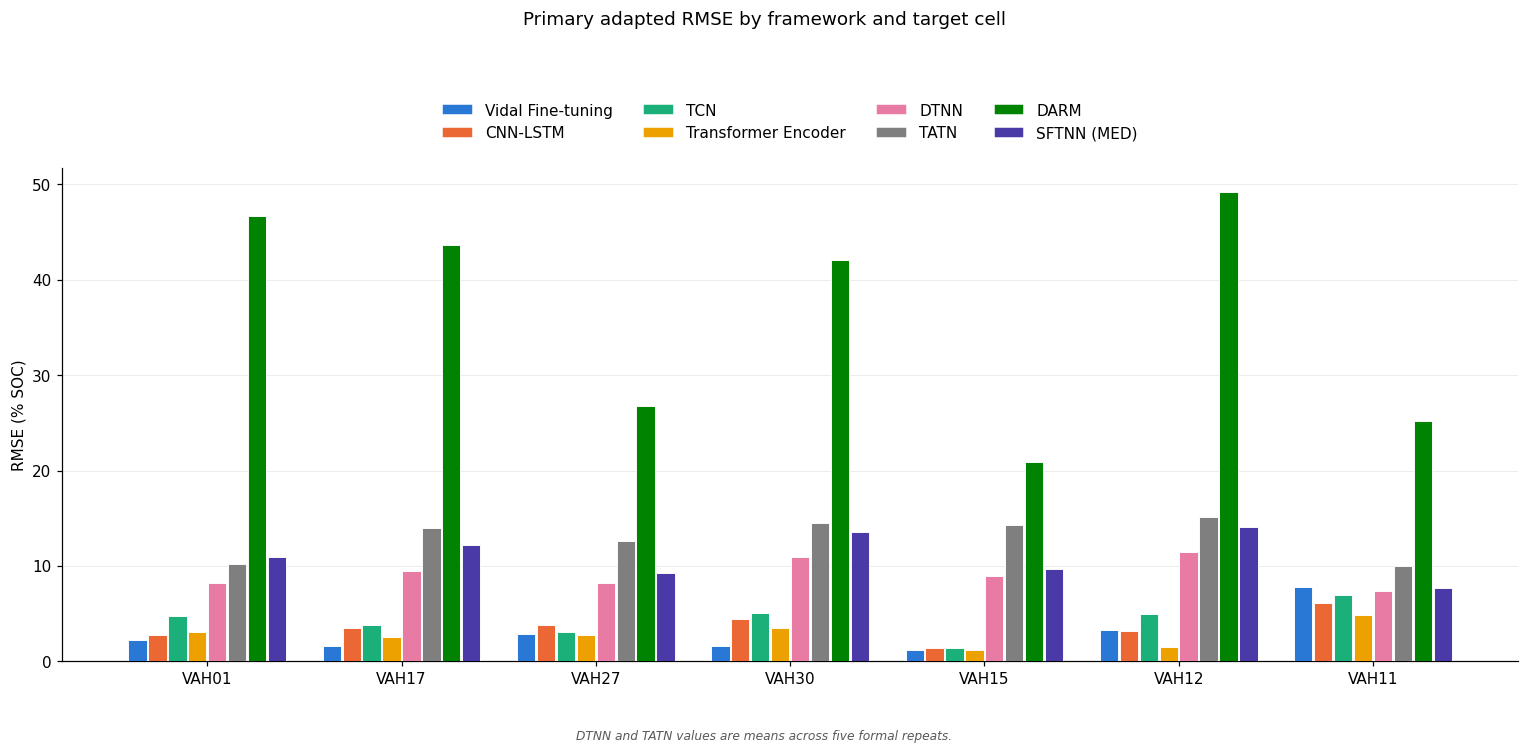

In [41]:
"""Code Cell -- RMSE grouped bar chart."""

fig_rmse, ax_rmse = plot_primary_adapted_bar_chart(
    metric_col="rmse",
    y_label="RMSE (% SOC)",
    title="Primary adapted RMSE by framework and target cell",
    out_stem=FIGURES_DIR / "primary_adapted_rmse_bar",
)
plt.show()


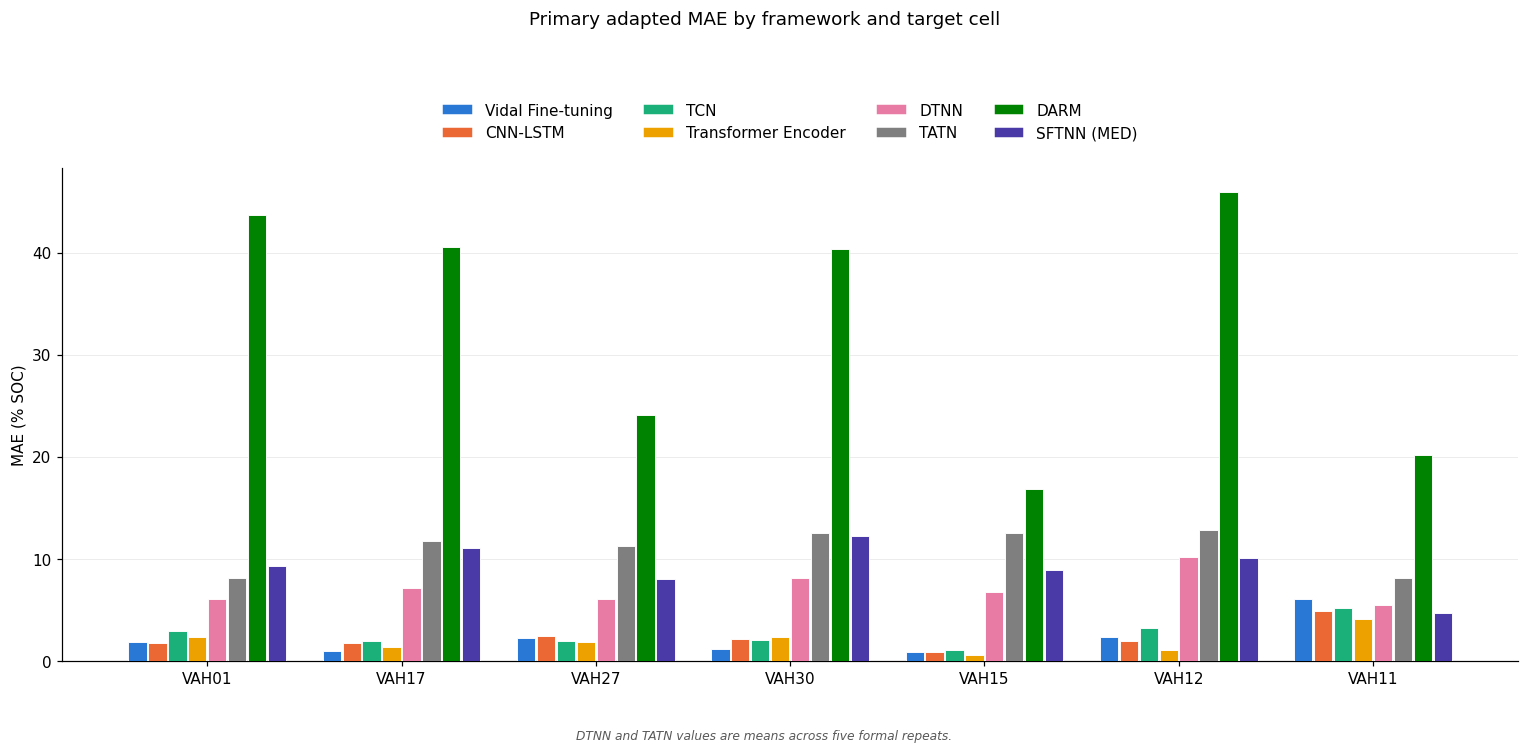

In [42]:
"""Code Cell -- MAE grouped bar chart."""

fig_mae, ax_mae = plot_primary_adapted_bar_chart(
    metric_col="mae",
    y_label="MAE (% SOC)",
    title="Primary adapted MAE by framework and target cell",
    out_stem=FIGURES_DIR / "primary_adapted_mae_bar",
)
plt.show()


In [43]:
"""Code Cell -- confirm bar-chart exports."""

print("Wrote:")
for p in sorted(FIGURES_DIR.glob("primary_adapted_*")):
    print(" ", p)
print(" ", OUTPUT_DIR / "primary_adapted_metrics_long.csv")


Wrote:
  metric_table_outputs/figures/primary_adapted_mae_bar.pdf
  metric_table_outputs/figures/primary_adapted_mae_bar.png
  metric_table_outputs/figures/primary_adapted_rmse_bar.pdf
  metric_table_outputs/figures/primary_adapted_rmse_bar.png
  metric_table_outputs/primary_adapted_metrics_long.csv


## Deferred (not in this pass)

Budget-sweep bar charts (1% / 5% / 10% / 40% / Full), stacked bars,
box/violin plots, significance tests, heatmaps, and phase-/mission-wise
charts are all out of scope for this pass -- only the two Primary-adapted
grouped bar charts above.